# Agency performance: where should management intervene?

**Validated synthetic snapshot: 1 September 2026 · Reporting month: August 2026**

This notebook consumes PostgreSQL views from `sql/04_agency_performance.sql`.
SQL owns eligibility, targets, cohort conversion, activation, MoM and concentration.
Pandas selects, sorts and formats SQL outputs for decision-oriented charts.

Read [the metric contract](../docs/phase3_metric_definitions.md) and
[management findings](../docs/phase3_findings.md). Annualized premium is UGX contract
value, not cash or revenue. September is incomplete and excluded from monthly comparisons.
Current status is not persistency, and leads cannot be attributed directly to policies.

Before running: install `requirements-phase3.txt`, load the validated Phase 2
snapshot, install the Phase 3 SQL views, and set `DATABASE_URL`. Execute from the
repository root with `python src/execute_phase3_notebook.py`. The first code cell
revalidates source and PostgreSQL data in one repeatable-read transaction; a failed
gate stops the notebook before it can publish findings.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import psycopg
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from agency_performance import read_analysis
from dataset import connection_string

with psycopg.connect(connection_string()) as conn:
    conn.execute("SET TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY")
    data, evidence = read_analysis(conn)

display(
    pd.Series(
        {
            key: evidence[key]
            for key in (
                "as_of",
                "python_version",
                "postgresql_version",
                "validation_checks",
                "validation_failures",
                "production_reconciliation",
                "phase3_sql_sha256",
            )
        },
        name="Execution evidence",
    ).to_frame()
)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    }
)
BLUE, TEAL, ORANGE = "#235789", "#187D78", "#C77727"
FIGURES = ROOT / "data/processed/phase3/figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def numeric(frame, columns):
    # Type conversion only: metric formulas remain in SQL.
    result = frame.copy()
    for column in columns:
        result[column] = pd.to_numeric(result[column])
    return result


trends = data["monthly_trends"].sort_values("period_start")
latest = trends["period_start"].max()
current = data["performance"].query("period_start == @latest")
agents = data["agent_month"].query("period_start == @latest")
print(f"Complete-month coverage: {trends.period_start.min()} to {latest}")

,Execution evidence
as_of,2026-09-01
python_version,3.12.8
postgresql_version,170006
validation_checks,542
validation_failures,0
production_reconciliation,PASS: raw policies / Agency / Region / Unit / ...
phase3_sql_sha256,5a16af1691295ee1ab9857d57e11554ec03470c5799aa5...


Complete-month coverage: 2023-01-01 to 2026-08-01


## Overall Agency scorecard

Use producing-agent ratio for participation and policies per producer for output
among participants. Both are needed to distinguish intervention opportunities.
Target coverage is displayed alongside achievement; partial coverage would limit
comparability. NULL ratios mean the denominator is unavailable or zero.

In [2]:
score_columns = [
    "period_start",
    "eligible_agents",
    "producing_agents",
    "new_policies",
    "new_business_annualized_premium",
    "producing_agent_ratio",
    "policies_per_producing_agent",
    "avg_annualized_premium_per_policy",
    "policy_target",
    "premium_target",
    "agents_with_policy_target",
    "agents_with_premium_target",
    "policy_target_achievement",
    "premium_target_achievement",
    "policy_target_achievers",
    "premium_target_achievers",
    "leads_created",
    "converted_leads",
    "lead_conversion",
    "policy_mom_growth",
    "premium_mom_growth",
]
display(trends.tail(2)[score_columns].set_index("period_start").T)

period_start,2026-07-01,2026-08-01
eligible_agents,371,368
producing_agents,342,338
new_policies,1734,1662
new_business_annualized_premium,5322900000.00,5049720000.00
producing_agent_ratio,0.92183288409703504043,0.91847826086956521739
policies_per_producing_agent,5.0701754385964912,4.9171597633136095
avg_annualized_premium_per_policy,3069723.183391003460,3038339.350180505415
policy_target,4778.0,4825.0
premium_target,7168000000.00,6973600000.00
agents_with_policy_target,371,368


## Complete-month performance trends

The calendar includes months with zero production. September 2026 is absent.
Production trends are gross issued business; later policy status changes do not
erase historical sales. Target coverage begins in January 2025.

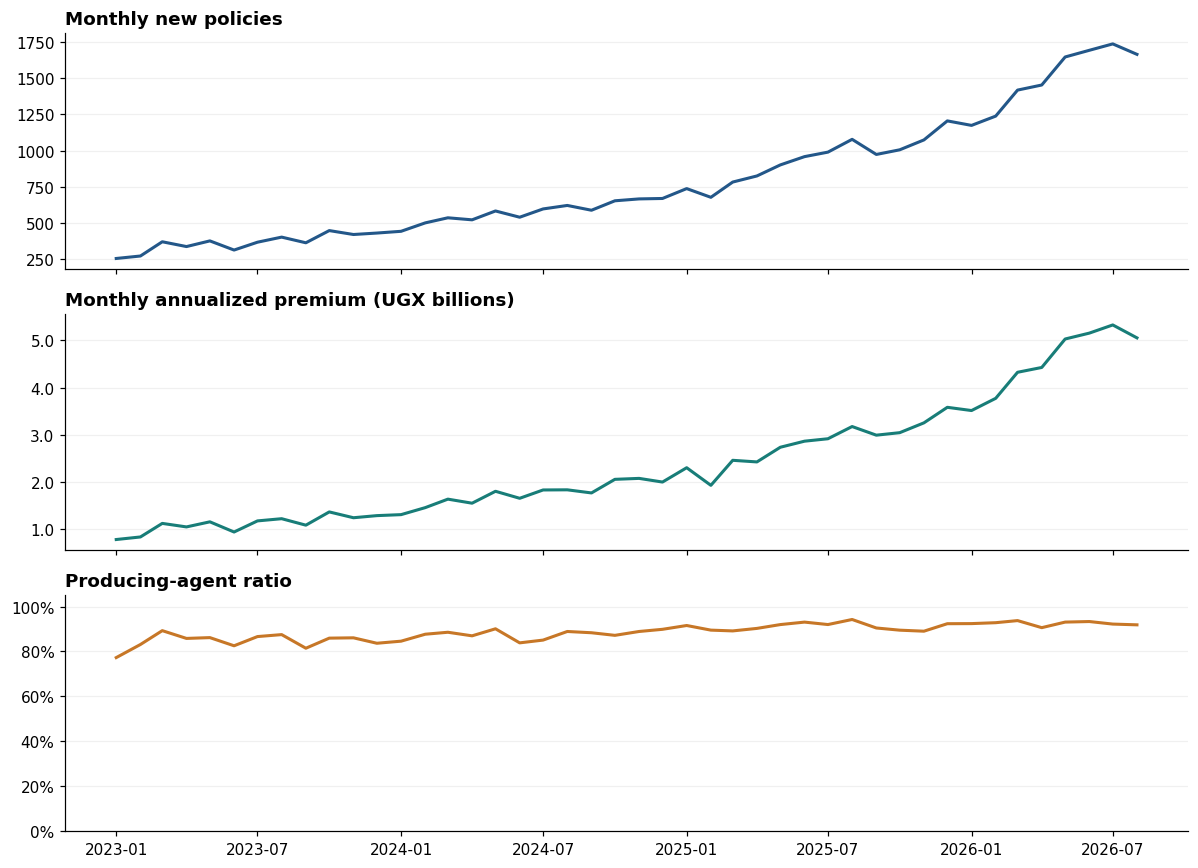

In [3]:
plot = numeric(trends, ["new_policies", "new_business_annualized_premium", "producing_agent_ratio"])
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, field, title, color in zip(
    axes,
    ["new_policies", "new_business_annualized_premium", "producing_agent_ratio"],
    ["Monthly new policies", "Monthly annualized premium (UGX billions)", "Producing-agent ratio"],
    [BLUE, TEAL, ORANGE],
    strict=True,
):
    ax.plot(plot.period_start, plot[field], color=color, linewidth=2)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", alpha=0.18)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1e9:.1f}"))
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[2].set_ylim(0, 1.05)
finish(fig, "01_monthly_trends")

## Regional sources of performance

Compare absolute production with participation and productivity before calling a
region stronger or weaker. Differences in eligible headcount affect volume.
Region and unit represent current assignment; historical transfers are unavailable.

,region,eligible_agents,producing_agents,new_policies,new_business_annualized_premium,producing_agent_ratio,policies_per_producing_agent,policy_target_achievement,premium_target_achievement
1046,Eastern,56,51,216.0,6.879000e+08,0.91071428571428571429,4.2352941176470588,0.30725462304409672831,0.69922748526123195771
1049,Northern,67,62,286.0,8.470200e+08,0.92537313432835820896,4.6129032258064516,0.32873563218390804598,0.65864696734059097978
1052,Western,64,62,340.0,1.002420e+09,0.96875000000000000000,5.4838709677419355,0.38857142857142857143,0.80212851084260222453
1043,Central,181,163,820.0,2.512380e+09,0.90055248618784530387,5.0306748466257669,0.34497265460664703408,0.72736168611215656756


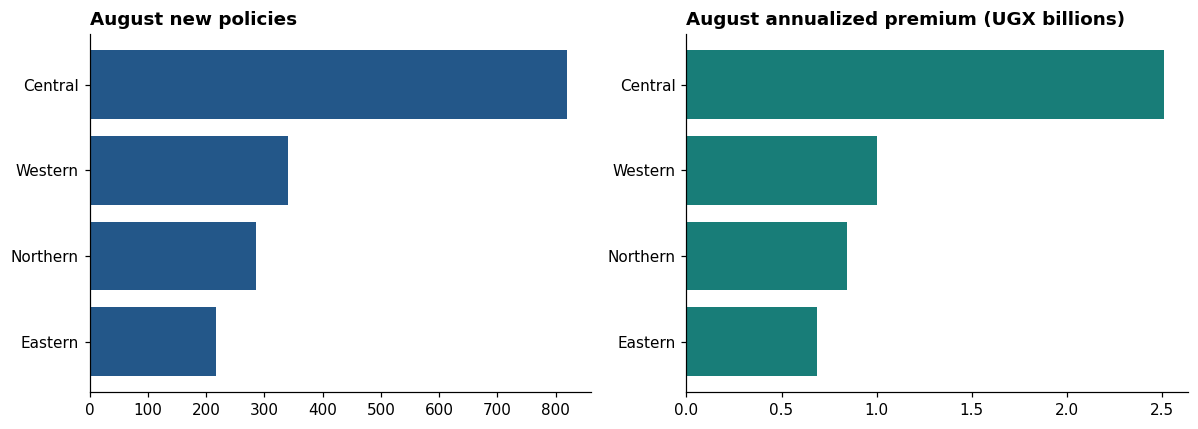

In [4]:
regions = numeric(
    current.query("grain == 'Region'").sort_values("new_policies"),
    ["new_policies", "new_business_annualized_premium"],
)
display(
    regions[
        [
            "region",
            "eligible_agents",
            "producing_agents",
            "new_policies",
            "new_business_annualized_premium",
            "producing_agent_ratio",
            "policies_per_producing_agent",
            "policy_target_achievement",
            "premium_target_achievement",
        ]
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(regions.region, regions.new_policies, color=BLUE)
axes[0].set_title("August new policies", loc="left")
axes[1].barh(regions.region, regions.new_business_annualized_premium, color=TEAL)
axes[1].set_title("August annualized premium (UGX billions)", loc="left")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1e9:.1f}"))
finish(fig, "02_regions")

## Agency units: targets and intervention priorities

The 100% reference line is the defined target, not an invented risk threshold.
The scatter separates monthly activation from productivity. Use agent details to
investigate low-output units; this comparison alone does not establish causes.

,agency_name,eligible_agents,producing_agents,new_policies,agents_with_policy_target,agents_with_premium_target,policy_target_achievement,premium_target_achievement,producing_agent_ratio,policies_per_producing_agent
1047,Gulu,29,26,74,29,29,0.201087,0.426728,0.896552,2.846154
1042,Masaka,24,20,89,24,24,0.249300,0.556204,0.833333,4.450000
1038,Kampala East,34,30,116,34,34,0.259508,0.577427,0.882353,3.866667
1044,Jinja,25,24,98,25,25,0.300613,0.646824,0.960000,4.083333
1045,Mbale,31,27,118,31,31,0.312997,0.745493,0.870968,4.370370
1037,Kampala Central,28,26,132,28,28,0.338462,0.671511,0.928571,5.076923
1041,Entebbe,22,22,93,22,22,0.339416,0.721975,1.000000,4.227273
1051,Fort Portal,39,37,179,39,39,0.358717,0.781395,0.948718,4.837838
1040,Wakiso,36,31,154,36,36,0.363208,0.729883,0.861111,4.967742
1048,Lira,38,36,212,38,38,0.422311,0.816492,0.947368,5.888889


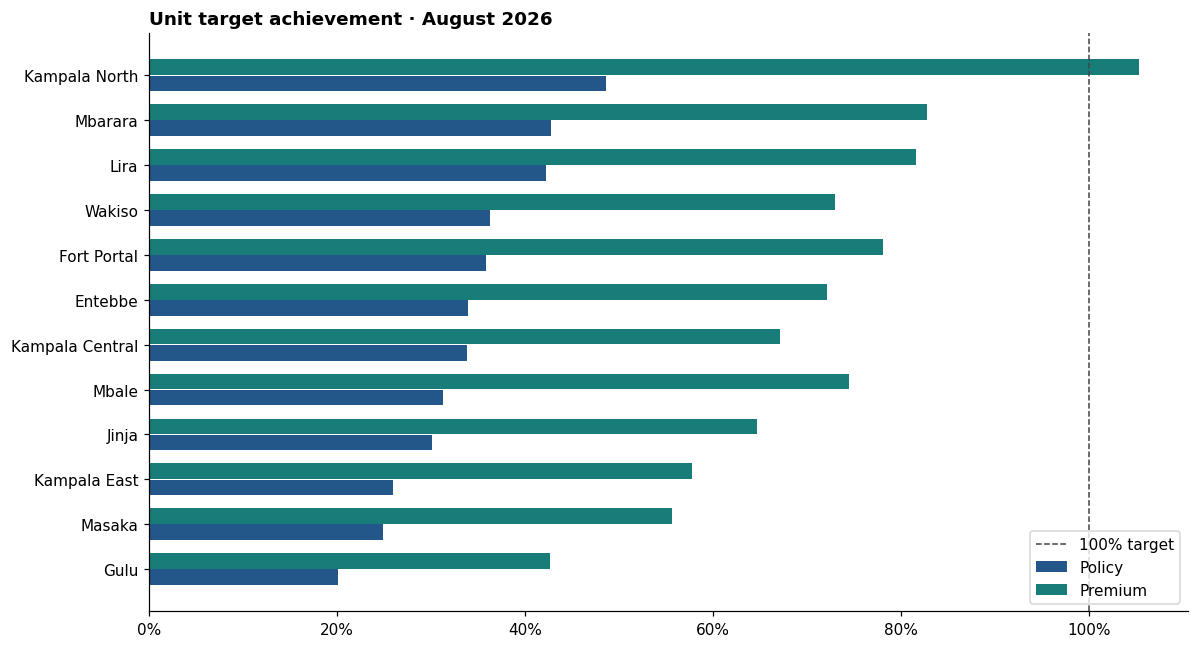

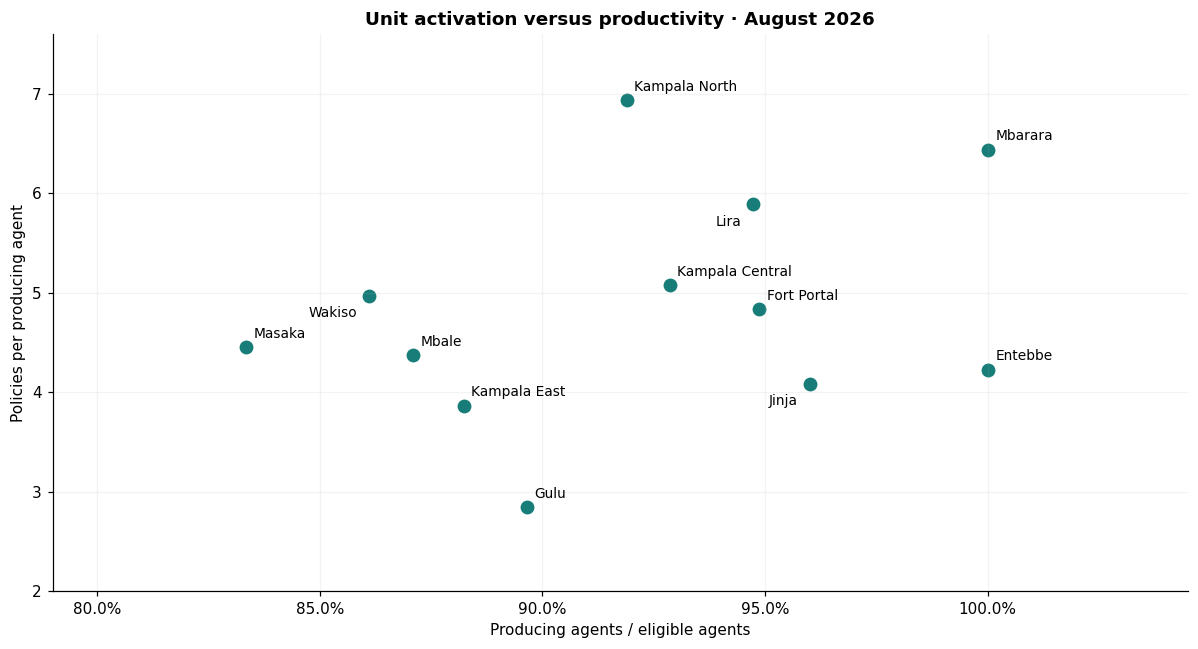

In [5]:
units = numeric(
    current.query("grain == 'Unit'").sort_values("policy_target_achievement"),
    [
        "policy_target_achievement",
        "premium_target_achievement",
        "producing_agent_ratio",
        "policies_per_producing_agent",
    ],
)
display(
    units[
        [
            "agency_name",
            "eligible_agents",
            "producing_agents",
            "new_policies",
            "agents_with_policy_target",
            "agents_with_premium_target",
            "policy_target_achievement",
            "premium_target_achievement",
            "producing_agent_ratio",
            "policies_per_producing_agent",
        ]
    ]
)
fig, ax = plt.subplots(figsize=(11, 6))
y = list(range(len(units)))
ax.barh(
    [v - 0.18 for v in y], units.policy_target_achievement, height=0.35, color=BLUE, label="Policy"
)
ax.barh(
    [v + 0.18 for v in y],
    units.premium_target_achievement,
    height=0.35,
    color=TEAL,
    label="Premium",
)
ax.set_yticks(y, units.agency_name)
ax.axvline(1, color="#444444", linestyle="--", linewidth=1, label="100% target")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Unit target achievement · August 2026", loc="left")
ax.legend(loc="lower right")
finish(fig, "03_unit_targets")

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(units.producing_agent_ratio, units.policies_per_producing_agent, color=TEAL, s=65)
for row in units.itertuples():
    offset = (-8, -14) if row.agency_name in ("Jinja", "Lira", "Wakiso") else (5, 6)
    ax.annotate(
        row.agency_name,
        (row.producing_agent_ratio, row.policies_per_producing_agent),
        xytext=offset,
        textcoords="offset points",
        fontsize=9,
        ha="right" if offset[0] < 0 else "left",
    )
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(
    xlabel="Producing agents / eligible agents",
    ylabel="Policies per producing agent",
    title="Unit activation versus productivity · August 2026",
    xlim=(0.79, 1.045),
    ylim=(2, 7.6),
)
ax.grid(alpha=0.15)
finish(fig, "04_activation_productivity")

## Agent performance and separate target distributions

The table shows the top ten agents by policy count, with agent_id breaking ties;
the full agent/month export retains all agents. The two target distributions must
not be combined: a policy achiever may miss the premium target and vice versa.
Missing/invalid targets remain a separate category, including for non-producers.

,agent_id,agency_name,agent_grade,new_policies,new_business_annualized_premium,policy_target_achievement,premium_target_achievement,policy_target_band,premium_target_band
11651,A0098,Lira,Trainee,32,110340000.00,1.8823529411764706,4.6953191489361702,High Achiever,High Achiever
11482,A0260,Kampala North,Trainee,32,98700000.00,2.1333333333333333,4.8146341463414634,High Achiever,High Achiever
11555,A0166,Kampala North,Trainee,31,88800000.00,1.4090909090909091,3.3011152416356877,High Achiever,High Achiever
11690,A0341,Lira,Trainee,28,70140000.00,1.5555555555555556,2.4610526315789474,High Achiever,High Achiever
11714,A0197,Fort Portal,Trainee,27,79740000.00,1.5882352941176471,3.1148437500000000,High Achiever,High Achiever
11713,A0022,Mbarara,Trainee,26,80040000.00,1.3684210526315789,2.7986013986013986,High Achiever,High Achiever
11652,A0096,Lira,Trainee,24,80220000.00,1.4117647058823529,3.0853846153846154,High Achiever,High Achiever
11560,A0302,Kampala Central,Trainee,21,64380000.00,1.1666666666666667,2.7050420168067227,Target Achiever,High Achiever
11529,A0252,Wakiso,Trainee,20,59280000.00,1.4285714285714286,3.7050000000000000,High Achiever,High Achiever
11763,A0396,Mbarara,Junior,20,54720000.00,1.1111111111111111,1.6888888888888889,Target Achiever,High Achiever


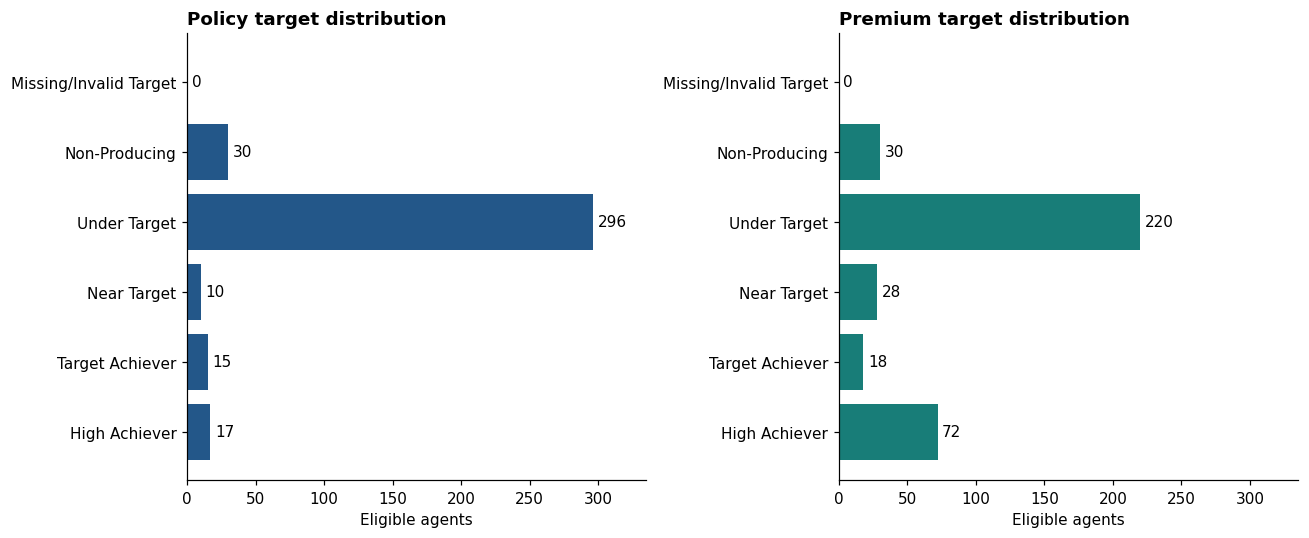

In [6]:
display(
    agents.sort_values(["new_policies", "agent_id"], ascending=[False, True]).head(10)[
        [
            "agent_id",
            "agency_name",
            "agent_grade",
            "new_policies",
            "new_business_annualized_premium",
            "policy_target_achievement",
            "premium_target_achievement",
            "policy_target_band",
            "premium_target_band",
        ]
    ]
)
bands = [
    "Missing/Invalid Target",
    "Non-Producing",
    "Under Target",
    "Near Target",
    "Target Achiever",
    "High Achiever",
]
distribution = data["target_distribution"].query("period_start == @latest")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, target, color in zip(axes, ["Policy", "Premium"], [BLUE, TEAL], strict=True):
    subset = distribution.query("target_type == @target").set_index("target_band").reindex(bands)
    counts = subset.agents.fillna(0).astype(int)  # Absent category = zero observations.
    ax.barh(bands, counts, color=color)
    ax.bar_label(ax.containers[0], padding=3)
    ax.set_title(f"{target} target distribution", loc="left")
    ax.set_xlabel("Eligible agents")
    ax.set_xlim(0, 335)
    ax.invert_yaxis()
finish(fig, "05_target_distributions")

## Lead Stage Evidence

These are recorded stage counts for leads **created in August**, measured at
September 1. Booking includes completed/no-show appointments; submission includes
approved/declined/withdrawn applications. Counts are not timestamped transitions.
Approved applications can lack completed appointment evidence, so counts need not
nest. Each stage share uses the same full creation-cohort denominator.

Recent cohorts have less time to convert (cohort maturity bias). No chart here
claims direct lead-to-policy attribution or sequential stage conversion rates.

,stage,leads,leads_created,share_of_cohort
301,Lead,3349,3349,1.00000000000000000000
302,Contacted,2642,3349,0.78889220662884443117
303,Appointment Booked,2642,3349,0.78889220662884443117
304,Appointment Completed,1189,3349,0.35503135264257987459
305,Application Submitted,988,3349,0.29501343684681994625
306,Application Approved,776,3349,0.23171095849507315617
307,Converted,776,3349,0.23171095849507315617


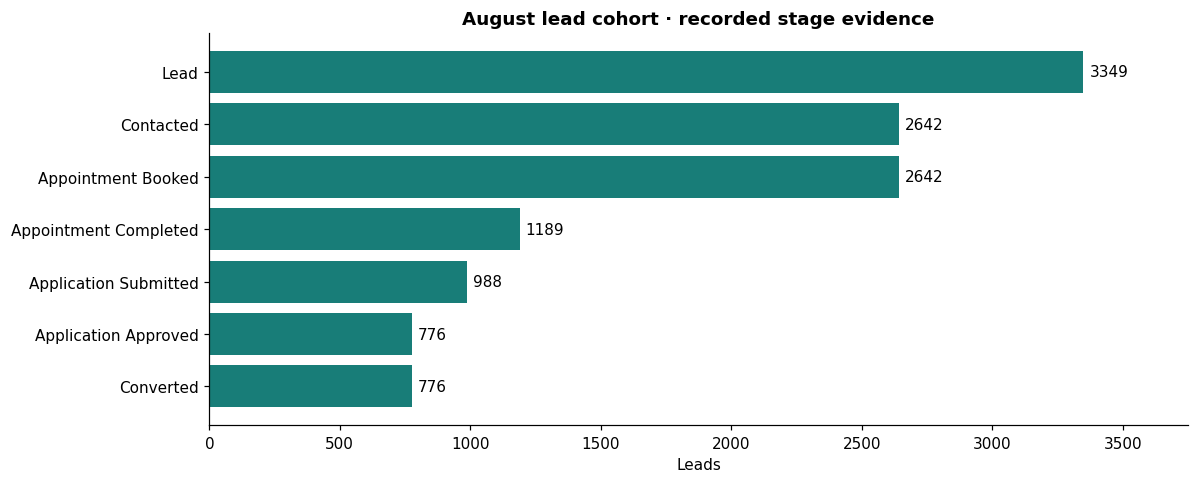

In [7]:
funnel = data["lead_funnel"].query("period_start == @latest").sort_values("stage_order")
display(funnel[["stage", "leads", "leads_created", "share_of_cohort"]])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(funnel.stage, funnel.leads.astype(int), color=TEAL)
ax.bar_label(ax.containers[0], padding=4)
ax.invert_yaxis()
ax.set(title="August lead cohort · recorded stage evidence", xlabel="Leads")
ax.set_xlim(0, 3750)
finish(fig, "06_lead_funnel")

## Recruitment activation and time to first policy

For recruits joining on/after January 1, 2023, first-30-day activation requires
observable recruitment history, a mature 30-day window, and service through day 29.
Earlier recruits are left-censored. Ineligible recruits return NULL; eligible
recruits with no policy in days 0–29 return False. Exclusion flags may overlap.
The median days to first policy describes observed producers only and is not a
survival estimate. Recruitment-month rates show their denominators in the table.

,0
recruits,400
left_censored_agents,126
immature_agents,0
early_exit_agents,0
first_30_day_eligible_agents,274
activated_first_30_day_agents,257
first_30_day_activation_ratio,0.93795620437956204380
median_observed_days_to_first_policy,7.0


,recruitment_month,recruits,left_censored_agents,immature_agents,early_exit_agents,first_30_day_eligible_agents,activated_first_30_day_agents,first_30_day_activation_ratio,median_observed_days_to_first_policy
53,2025-06-01,7,0,0,0,7,7,1.0,7.0
54,2025-07-01,8,0,0,0,8,8,1.0,1.5
55,2025-08-01,5,0,0,0,5,5,1.0,4.0
56,2025-09-01,6,0,0,0,6,6,1.0,4.0
57,2025-10-01,8,0,0,0,8,8,1.0,7.0
58,2025-11-01,5,0,0,0,5,5,1.0,2.0
59,2025-12-01,8,0,0,0,8,8,1.0,3.5
60,2026-01-01,3,0,0,0,3,3,1.0,8.0
61,2026-02-01,7,0,0,0,7,7,1.0,3.0
62,2026-03-01,9,0,0,0,9,9,1.0,2.0


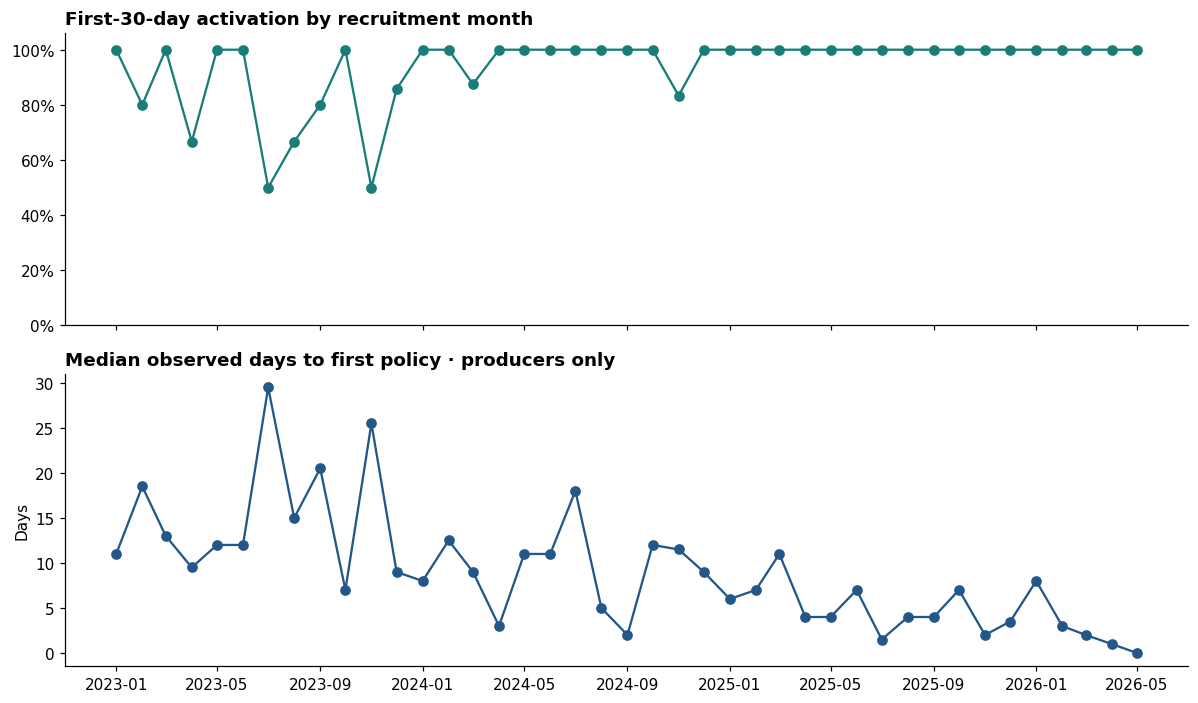

In [8]:
display(data["activation_summary"].T)
cohorts = numeric(
    data["activation_cohorts"].sort_values("recruitment_month"),
    ["first_30_day_activation_ratio", "median_observed_days_to_first_policy"],
)
display(cohorts.tail(12))
observable = cohorts.query("first_30_day_eligible_agents > 0")
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(
    observable.recruitment_month, observable.first_30_day_activation_ratio, marker="o", color=TEAL
)
axes[0].set_title("First-30-day activation by recruitment month", loc="left")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_ylim(0, 1.06)
axes[1].plot(
    observable.recruitment_month,
    observable.median_observed_days_to_first_policy,
    marker="o",
    color=BLUE,
)
axes[1].set_title("Median observed days to first policy · producers only", loc="left")
axes[1].set_ylabel("Days")
finish(fig, "07_recruit_activation")

## Tenure and grade: descriptive associations

Tenure is measured at the reporting-period end in disclosed 0–<6, 6–<12, 12–<24
and 24+ month bands. Grade is the current recorded grade, not historical grade.
The synthetic generator derives grade from tenure and allocates observations
across agents' available service windows. Shorter windows can concentrate recent
production; these patterns do not prove new recruits are inherently more capable.

,eligible_agents,producing_agents,new_policies,producing_agent_ratio,policies_per_producing_agent
tenure_band,,,,,
0-<6 months,19,19,399,1.00000000000000000000,21.000000
6-<12 months,36,36,354,1.00000000000000000000,9.833333
12-<24 months,75,74,336,0.98666666666666666667,4.540541
24+ months,238,209,573,0.87815126050420168067,2.741627


,eligible_agents,producing_agents,new_policies,producing_agent_ratio,policies_per_producing_agent
agent_grade,,,,,
Trainee,19,19,399,1.00000000000000000000,21.000000
Junior,49,49,429,1.00000000000000000000,8.755102
Standard,90,89,352,0.98888888888888888889,3.955056
Senior,118,108,305,0.91525423728813559322,2.824074
Elite,92,73,177,0.79347826086956521739,2.424658


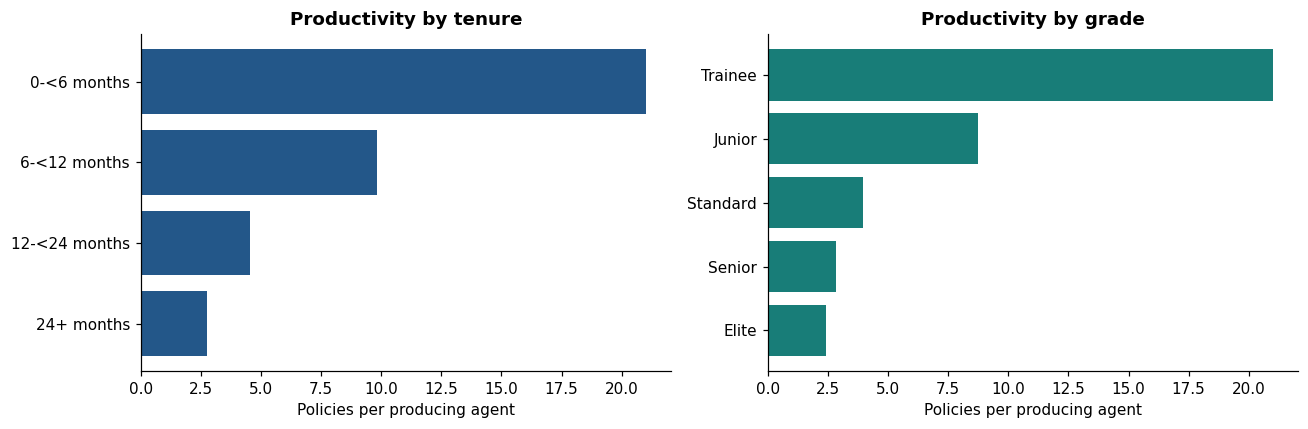

In [9]:
tenure_order = ["0-<6 months", "6-<12 months", "12-<24 months", "24+ months"]
grade_order = ["Trainee", "Junior", "Standard", "Senior", "Elite"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grain, field, order in zip(
    axes,
    ["Tenure", "Grade"],
    ["tenure_band", "agent_grade"],
    [tenure_order, grade_order],
    strict=True,
):
    subset = numeric(current.query("grain == @grain"), ["policies_per_producing_agent"])
    subset = subset.set_index(field).reindex(order)
    display(
        subset[
            [
                "eligible_agents",
                "producing_agents",
                "new_policies",
                "producing_agent_ratio",
                "policies_per_producing_agent",
            ]
        ]
    )
    ax.barh(order, subset.policies_per_producing_agent, color=BLUE if grain == "Tenure" else TEAL)
    ax.invert_yaxis()
    ax.set(title=f"Productivity by {grain.lower()}", xlabel="Policies per producing agent")
finish(fig, "08_tenure_grade")

## Production concentration

Each month selects CEIL(10% × producing agents), ranked independently by policy
count and premium, with agent_id breaking ties. The selected group size is exposed;
the two top groups need not contain the same agents. Concentration identifies
production dependency, not evidence of future agent departures.

,period_start,top_agent_count,producing_agents,top_policy_share,top_premium_share
42,2026-07-01,35,342,0.362745,0.361900
43,2026-08-01,34,338,0.365824,0.370832


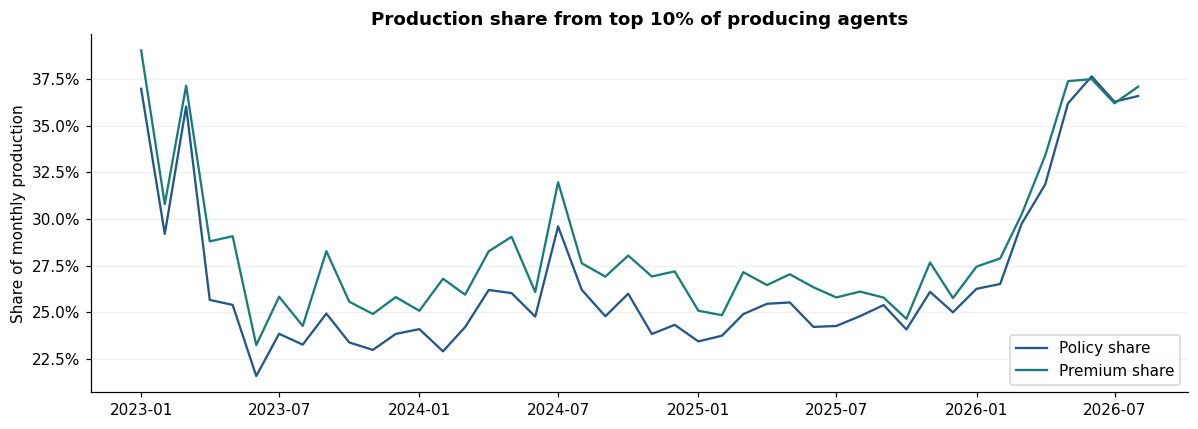

In [10]:
concentration = numeric(
    data["concentration"].sort_values("period_start"), ["top_policy_share", "top_premium_share"]
)
display(concentration.tail(2))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    concentration.period_start, concentration.top_policy_share, color=BLUE, label="Policy share"
)
ax.plot(
    concentration.period_start, concentration.top_premium_share, color=TEAL, label="Premium share"
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(
    title="Production share from top 10% of producing agents", ylabel="Share of monthly production"
)
ax.legend()
ax.grid(axis="y", alpha=0.18)
finish(fig, "09_concentration")

## Management interpretation from the executed snapshot

**Observation:** August policy and annualized-premium production fell from July,
while the majority of eligible agents produced at least one policy.
**Diagnosis:** Participation alone does not explain the target shortfall; policies
per producer and the available target levels also matter. This is descriptive.
**Business implication:** A blanket activation campaign would address only one
part of the shortfall. **Possible management action:** Review producer output and
target assumptions alongside focused follow-up with non-producers.

**Observation:** Units differ in participation, productivity and the balance of
policy versus premium achievement. **Diagnosis:** Absolute rankings combine team
size and per-producer output; premium and volume targets assess different outcomes.
**Business implication:** One ranking cannot determine every intervention.
**Possible management action:** Use the unit scatter and both target measures to
prioritize reviews, then inspect the full agent export.

**Observation:** Newer tenure/grade groups have high observed production and the
top producer groups contribute a substantial share. **Diagnosis:** Generator
construction and shorter service windows affect these patterns; they are not
causal evidence of skill. **Business implication:** Avoid changing incentives or
recruitment policy from this simulation alone. **Possible management action:**
Validate patterns in longitudinal operational data and investigate practices that
could be tested with broader cohorts.

The [findings document](../docs/phase3_findings.md) records exact executed values,
the evidence files and detailed interventions. This notebook does not infer
persistency, cash collection, lead-to-policy attribution or causal relationships.